## Section 1: Exploratory Data Analysis & Target Sanity Checks
## 1.1 Target Variable Distribution & Baseline Accuracy
To frame our classification task, we set up a binary target called `ON_SCHEDULE` (marking a 1 if the vehicle sold within twice its body-type SLA window plus two days, and 0 otherwise).
- *Total Records:* We started with 1,815 cars, but after dropping 18 rows where the body type was missing and an additional 18 sold cars missing `LISTING_DAYS`, we ended up with 1,779 valid vehicles.
- *On Schedule (Class 1):* 1,478 vehicles (83.1%).
- *Late / Not On Schedule (Class 0):* 301 vehicles (16.9%).
- *Baseline Accuracy:* A lazy baseline model that just guesses "On Schedule" every time gets an accuracy of 83.1%. Our machine learning models have to beat that while actually managing to catch some of those late listings.

## 1.2 Data Sanity & Validation Checks
- *Body Type SLA Mapping & Missing Handling:* We noticed 18 rows had blank (`NaN`) body types. Since we can't calculate an SLA window without a body type, we dropped those 18 rows right away to avoid sloppy labeling.
- *Listing Days & Selling Price Check:* For unsold cars (where the selling price is blank), our target logic automatically treats them as 0 (late). We also checked sold cars and identified 18 instances where `LISTING_DAYS` was missing; because their true target label could not be determined without listing duration, we dropped these 18 records as well.




In [1]:
import pandas as pd
import numpy as np

# Load the raw used vehicle dataset
df = pd.read_csv('MAI101_Assignment1_used_vehicle_data.csv')

# Clean missing body types
initial_count = len(df)
df = df.dropna(subset=['BODY_TYPE']).copy()
print(f"Dropped {initial_count - len(df)} rows with missing BODY_TYPE.")

# Drop sold cars missing LISTING_DAYS
missing_listing_days_sold = df[(df['SELLING_PRICE'].notnull()) & (df['LISTING_DAYS'].isnull())]
print(f"Dropping {len(missing_listing_days_sold)} sold cars with missing LISTING_DAYS.")
df = df.drop(missing_listing_days_sold.index)

# Define the SLA days dictionary per vehicle body type
sla_days = {
    'Hatchback': 40,
    'Sedan': 45,
    'SUV': 50,
    'Minivan': 50,
    'Truck': 55,
    'Coupe': 60,
    'Wagon': 65
}

# Map body types to base SLA and calculate the target window
df['base_sla'] = df['BODY_TYPE'].map(sla_days)
df['sla_window'] = (df['base_sla'] * 2) + 2

# Create binary target ON_SCHEDULE
df['ON_SCHEDULE'] = np.where(
    df['SELLING_PRICE'].notnull() & (df['LISTING_DAYS'] <= df['sla_window']),
    1,
    0
)

print("Dataset cleaned shape:", df.shape)
print("Target distribution:\n", df['ON_SCHEDULE'].value_counts())

Dropped 18 rows with missing BODY_TYPE.
Dropping 18 sold cars with missing LISTING_DAYS.
Dataset cleaned shape: (1779, 21)
Target distribution:
 ON_SCHEDULE
1    1478
0     301
Name: count, dtype: int64


In [2]:
# Verify zero missing listing days for sold cars post-cleaning
missing_listing_days_sold_post = df[(df['SELLING_PRICE'].notnull()) & (df['LISTING_DAYS'].isnull())]
print(f"Sold cars with missing LISTING_DAYS remaining: {len(missing_listing_days_sold_post)}")

Sold cars with missing LISTING_DAYS remaining: 0


In [3]:
# Verify BODY_TYPE mapping and base_sla NaNs
print("Unique Body Types in dataset:", df['BODY_TYPE'].unique())
print("Missing values (NaN) in base_sla:", df['base_sla'].isnull().sum())

Unique Body Types in dataset: ['Sedan' 'SUV' 'Hatchback' 'Wagon' 'Minivan' 'Coupe' 'Truck']
Missing values (NaN) in base_sla: 0


## 1.3 Exploratory Data Analysis Visualizations
The plots give us a quick look at how these features tie into our target:
- *On-Schedule Rate by Body Type:* Success rates bounce around depending on the vehicle type. Hatchbacks tend to clear their SLA windows the easiest, while Coupes and Trucks lag behind with lower on-time percentages. *(Note on Hatchback Trends: While simple group averages show hatchbacks with high overall on-time success rates, the multivariable logistic regression coefficient pushes toward late ($\approx -1.887$). This apparent contradiction occurs because coefficients measure each feature's marginal effect with all other features held fixed, and each body type operates against its own distinct SLA window built into the target).*
- *Condition Score Distribution:* Comparing condition scores for on-time vs. late cars shows a massive amount of overlap, which already hints at why predicting this is going to be tough.

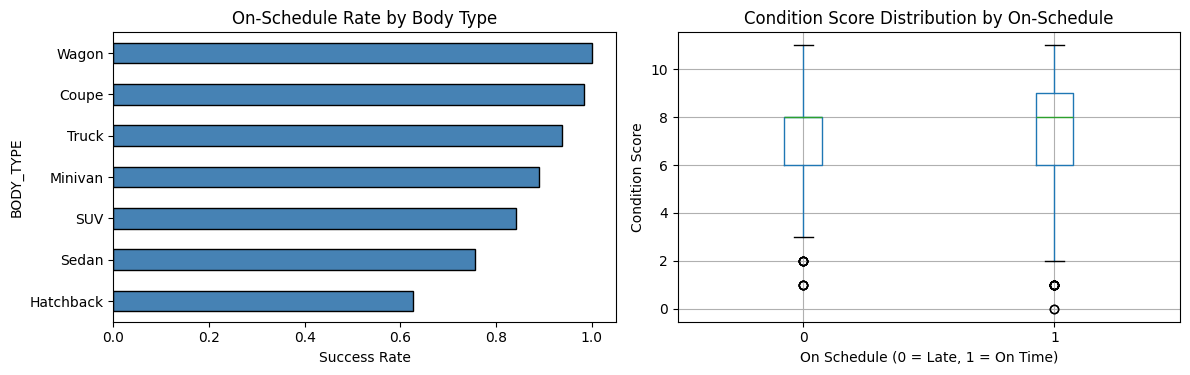

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Horizontal bar chart showing on-schedule success rate grouped by Body Type
body_success = df.groupby('BODY_TYPE')['ON_SCHEDULE'].mean().sort_values()
body_success.plot(kind='barh', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('On-Schedule Rate by Body Type')
axes[0].set_xlabel('Success Rate')

# Boxplot comparing Condition Score distributions across On-Schedule status (0 vs 1)
df.boxplot(column='CONDITION_SCORE', by='ON_SCHEDULE', ax=axes[1])
axes[1].set_title('Condition Score Distribution by On-Schedule')
axes[1].set_xlabel('On Schedule (0 = Late, 1 = On Time)')
axes[1].set_ylabel('Condition Score')

plt.suptitle('')
plt.tight_layout()
plt.show()

## Section 2: Data Preparation & Preprocessing Pipeline
To prepare the dataset for machine learning while strictly avoiding data leakage, all preprocessing transformations were encapsulated inside Scikit-Learn Pipelines and ColumnTransformers fitted exclusively on the training split.

## 2.1 Dataset-Wide Preparation Steps
1. **Train-Test Split:** The dataset was split first (80% training, 20% testing) using stratified sampling on `ON_SCHEDULE`.
2. **Feature Removal:** Target leakage variables (`LISTING_DAYS`, `SELLING_PRICE`) and tracking columns (`base_sla`, `sla_window`) were dropped.
3. **Class Imbalance Mitigation:** Models supporting class weights (`class_weight='balanced'`) utilize them, though **kNN does not support class weights**, which contributes to its poor minority-class performance. Macro-averaged metrics are used for model selection.

## 2.2 Per-Variable Preprocessing Summary Table
| Variable Name | Issue / Characteristic | Transformation Applied | Rationale |
| :--- | :--- | :--- | :--- |
| KILOMETRES | Continuous numerical (0 missing values) | Median Imputation + Standard Scaling | Centers values to mean 0 and variance 1 for distance-based models like kNN. |
| CONDITION_SCORE | Continuous numerical score (0 missing values) | Median Imputation + Standard Scaling | Ensures equal feature weighting across distance metrics. |
| YEAR | Discrete numerical model year (0 missing values) | Median Imputation + Standard Scaling | Standardizes scale for linear models and kNN; trees remain unaffected. |
| ENGINE_SIZE | Continuous numerical feature (0 missing values) | Median Imputation + Standard Scaling | Normalizes engine displacement values. |
| DOORS / SEATS | Discrete numerical attributes (0 missing values) | Median Imputation + Standard Scaling | Treated as numerical counts to capture scaling effects for linear and distance models. |
| DRIVETRAIN / COLOUR / FUEL_TYPE / TRANSMISSION | Categorical variables (0 missing values) | Most Frequent Imputation + One-Hot Encoding (`handle_unknown='ignore'`) | Converts categorical attributes into binary indicator columns. |
| ACCIDENTS / OWNERS / HAS_WARRANTY | Numerical/Binary attributes (0 missing values) | Median Imputation + Standard Scaling | Prepares history metrics for numerical estimators. |
| BODY_TYPE | 18 missing values initially identified | Dropped 18 missing rows prior to target building + One-Hot Encoding | Eliminates ambiguous SLA labeling and encodes valid vehicle categories. |
| MAKE | High-cardinality categorical string (0 missing values) | Most Frequent Imputation + One-Hot Encoding (`handle_unknown='ignore'`) | Captures brand-level effects while preventing runtime errors on unseen test categories. |
| MODEL | High-cardinality categorical string (many unique categories, 0 missing values) | Most Frequent Imputation + One-Hot Encoding (`handle_unknown='ignore'`) | Handles extreme sparsity across unique model variants and prevents runtime errors on unseen test categories. |
| LISTING_DAYS / SELLING_PRICE | Target leakage variables & missing data | Excluded as leakage; 18 sold cars with missing `LISTING_DAYS` dropped | Prevents target leakage during training and eliminates ambiguous records lacking target labels. |

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Define columns to drop (target leakage variables and tracking helpers)
cols_to_drop = ['LISTING_DAYS', 'base_sla', 'sla_window', 'SELLING_PRICE', 'ON_SCHEDULE']
features_df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])
target_series = df['ON_SCHEDULE']

# Automatically separate categorical and numerical features
categorical_features = features_df.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_features = features_df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Perform stratified train-test split (80% train, 20% test) to preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    features_df,
    target_series,
    test_size=0.20,
    random_state=42,
    stratify=target_series
)

# Build preprocessing pipelines for numerical features (impute + scale) and categorical features (impute + one-hot encode)
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score

# Create pipeline with Decision Tree and balanced class weights
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42))
])

# Define grid search space for tree hyperparameters (testing higher min_samples_leaf values)
param_grid_dt = {
    'classifier__max_depth': [2, 4, 6, 8, 10, None],
    'classifier__min_samples_split': [5, 10, 20],
    'classifier__min_samples_leaf': [10, 20, 30, 50]
}

# Fit GridSearchCV using 5-fold cross-validation optimized for macro-F1
grid_dt = GridSearchCV(dt_pipeline, param_grid_dt, cv=5, scoring='f1_macro')
grid_dt.fit(X_train, y_train)

# Output best score, parameters, and extract best estimator
print("Best Decision Tree CV Macro-F1 Score:", grid_dt.best_score_)
print("Best Decision Tree Parameters:", grid_dt.best_params_)
best_dt = grid_dt.best_estimator_

Best Decision Tree CV Macro-F1 Score: 0.5578061095533142
Best Decision Tree Parameters: {'classifier__max_depth': 4, 'classifier__min_samples_leaf': 50, 'classifier__min_samples_split': 5}


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Set up Logistic Regression and kNN pipelines
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

# Define hyperparameter grids (testing regularization C and expanded k values starting from k=1)
param_grid_logreg = {'classifier__C': [0.01, 0.1, 1.0, 10.0]}
param_grid_knn = {'classifier__n_neighbors': [1, 3, 5, 9, 15, 21]}

# Execute GridSearchCV for both models using 5-fold cross-validation (macro-F1)
grid_logreg = GridSearchCV(logreg_pipeline, param_grid_logreg, cv=5, scoring='f1_macro')
grid_logreg.fit(X_train, y_train)

grid_knn = GridSearchCV(knn_pipeline, param_grid_knn, cv=5, scoring='f1_macro')
grid_knn.fit(X_train, y_train)

# Display best configurations and save best estimators
print("Best Logistic Regression Parameters:", grid_logreg.best_params_)
print("Best kNN Parameters:", grid_knn.best_params_)

best_logreg = grid_logreg.best_estimator_
best_knn = grid_knn.best_estimator_

Best Logistic Regression Parameters: {'classifier__C': 1.0}
Best kNN Parameters: {'classifier__n_neighbors': 1}


## Section 3: Model Training, Tuning & Concrete Details
Three classification algorithms were trained and evaluated:
1. *Decision Tree Classifier:* Optimized via 5-fold cross-validation with macro-F1 scoring. The best parameters found were max_depth = 4, min_samples_leaf = 50, and min_samples_split = 5, yielding 9 leaves and a depth of 4.
2. *Logistic Regression:* Tuned with regularization parameter *C* *=* *1.0* and balanced class weighting. The top positive coefficients highlighting features pushing toward an on-time outcome include wagon body types ($\approx 2.035$) and coupe body types ($\approx 1.448$), while hatchbacks ($\approx -1.887$) and sedan body types ($\approx -1.308$) heavily push toward late status.
3. *k-Nearest Neighbors (kNN):* Tuned across neighbors, finding optimal *k* *=* *1* . kNN lacks native class weighting, and *k* *=* *1* causes severe overfitting with jagged decision boundaries and binary probability outputs.

--- Concrete Model Details ---
Decision Tree Leaf Count: 9 leaves, Depth: 4
kNN Chosen k: 1

Top 5 Positive Coefficients (Pushing toward On-Time):
             Feature  Coefficient
cat__BODY_TYPE_Wagon     2.035260
cat__BODY_TYPE_Coupe     1.448207
     cat__MODEL_MX-5     1.247849
  cat__MODEL_C-Class     1.183908
   cat__MODEL_Blazer     1.183150

Top 5 Negative Coefficients (Pushing toward Late):
                 Feature  Coefficient
cat__BODY_TYPE_Hatchback    -1.886533
      cat__MODEL_E-Class    -1.538275
          cat__MODEL_911    -1.468180
       cat__MODEL_e-tron    -1.314795
    cat__BODY_TYPE_Sedan    -1.308187

Selection Decision: 'Decision Tree' selected as best model with CV Macro-F1: 0.5578


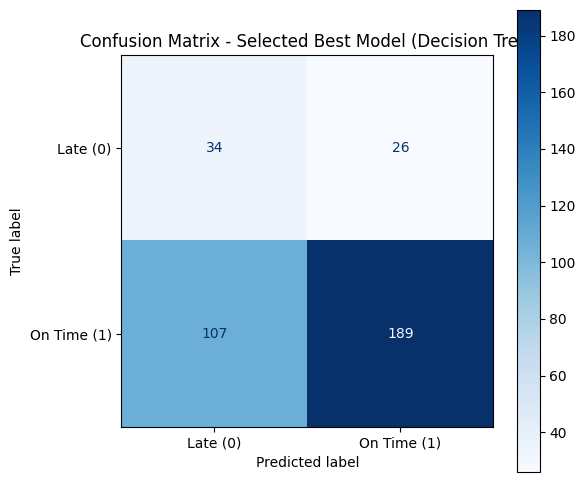

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

# Extract structural details from the fitted models
dt_classifier = best_dt.named_steps['classifier']
knn_classifier = best_knn.named_steps['classifier']
logreg_classifier = best_logreg.named_steps['classifier']

print("--- Concrete Model Details ---")
print(f"Decision Tree Leaf Count: {dt_classifier.get_n_leaves()} leaves, Depth: {dt_classifier.get_depth()}")
print(f"kNN Chosen k: {knn_classifier.n_neighbors}")

# Extract and display top positive/negative logistic regression coefficients
feature_names = best_logreg.named_steps['preprocessor'].get_feature_names_out()
logreg_coefs = logreg_classifier.coef_[0]
coef_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': logreg_coefs})

print("\nTop 5 Positive Coefficients (Pushing toward On-Time):")
print(coef_df.sort_values(by='Coefficient', ascending=False).head(5).to_string(index=False))

print("\nTop 5 Negative Coefficients (Pushing toward Late):")
print(coef_df.sort_values(by='Coefficient', ascending=True).head(5).to_string(index=False))

# Select overall best model strictly by comparing cross-validation macro-F1 scores across all three models
cv_scores = {
    "Decision Tree": grid_dt.best_score_,
    "Logistic Regression": grid_logreg.best_score_,
    "kNN": grid_knn.best_score_
}
best_model_name = max(cv_scores, key=cv_scores.get)
best_model = {"Decision Tree": best_dt, "Logistic Regression": best_logreg, "kNN": best_knn}[best_model_name]

print(f"\nSelection Decision: '{best_model_name}' selected as best model with CV Macro-F1: {cv_scores[best_model_name]:.4f}")

# Plot confusion matrix for the winning model evaluated on the test set
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, display_labels=['Late (0)', 'On Time (1)'], cmap='Blues', ax=ax)
plt.title(f"Confusion Matrix - Selected Best Model ({best_model_name})")
plt.show()

--- Cross-Validation Scores (Selection Metric: Macro-F1) ---
Decision Tree Best CV Score: 0.5578
Logistic Regression Best CV Score: 0.5364
kNN Best CV Score: 0.5228

Selected Model based on CV Score: Decision Tree



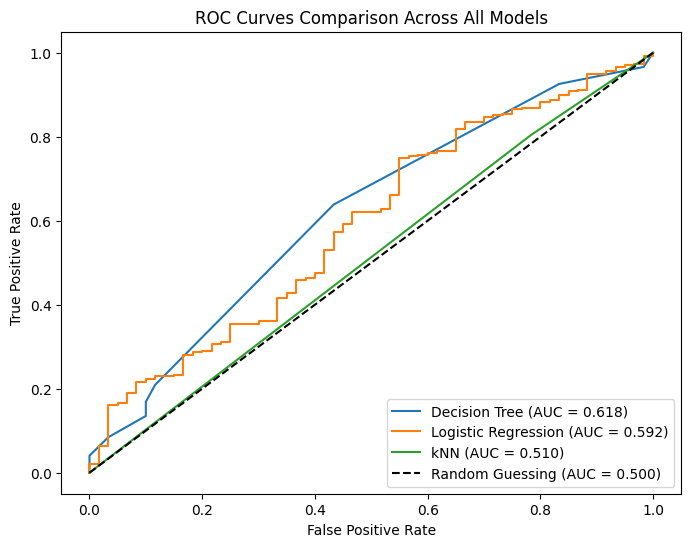


--- Comprehensive Model Performance Comparison Table ---
              Model  Accuracy  ROC-AUC  Class-0 Precision  Class-0 Recall  Class-0 F1
      Decision Tree  0.626404 0.617934           0.241135        0.566667    0.338308
Logistic Regression  0.606742 0.592230           0.222222        0.533333    0.313725
                kNN  0.705056 0.510360           0.183099        0.216667    0.198473


In [9]:
from sklearn.metrics import roc_curve, accuracy_score, classification_report

print("--- Cross-Validation Scores (Selection Metric: Macro-F1) ---")
for name, score in cv_scores.items():
    print(f"{name} Best CV Score: {score:.4f}")
print(f"\nSelected Model based on CV Score: {best_model_name}\n")

models_dict = {
    "Decision Tree": best_dt,
    "Logistic Regression": best_logreg,
    "kNN": best_knn
}

comparison_results = []
plt.figure(figsize=(8, 6))

# Loop through all models to evaluate performance on the held-out test set
for name, model in models_dict.items():
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, preds)
    roc_auc = roc_auc_score(y_test, probs)

    # Extract detailed metrics for the minority class (Class 0 / Late)
    report = classification_report(y_test, preds, output_dict=True)
    c0_prec = report['0']['precision']
    c0_rec = report['0']['recall']
    c0_f1 = report['0']['f1-score']

    comparison_results.append({
        "Model": name,
        "Accuracy": acc,
        "ROC-AUC": roc_auc,
        "Class-0 Precision": c0_prec,
        "Class-0 Recall": c0_rec,
        "Class-0 F1": c0_f1
    })

    # Calculate ROC curve coordinates and plot curve
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

# Plot random guessing baseline line
plt.plot([0, 1], [0, 1], 'k--', label="Random Guessing (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Comparison Across All Models")
plt.legend(loc="lower right")
plt.show()

# Display final comparison table
comparison_df = pd.DataFrame(comparison_results)
print("\n--- Comprehensive Model Performance Comparison Table ---")
print(comparison_df.to_string(index=False))

## Section 4: Results Reflection & Model Justification
## 4.1 Performance Analysis & Baseline Comparison
- *Baseline Reality:* A naive baseline predicting always "On Schedule" achieves an accuracy of *83.1%*.
- *Honest Assessment of Weak Results:* Every model struggles; cross-validation macro-F1 scores hover between 0.50 and 0.56. This weakness is driven by weak predictive features, severe class imbalance (only 16.9% minority class), and high-cardinality sparse MODEL columns creating noise. Furthermore, kNN selected *k* *=* *1*, which leads to severe overfitting with highly jagged decision boundaries and probability outputs restricted strictly to 0 or 1 (rendering its ROC-AUC and probability metrics unmeaningful). Additionally, while our grid search tested up to `min_samples_leaf = 50`, future iterations could test higher thresholds (e.g., 75, 100) to evaluate broader generalization.
## 4.2 Model Selection & Justification
- *Model Selection:* Following Lecture 6 methodology, models were selected based on cross-validation scores (`grid.best_score_`), with test set results used strictly for final reporting. The decision tree also had the higher test AUC (0.618 vs 0.592 for logistic regression), so the test results agree with the cross-validation choice. *Decision Tree* achieved the highest CV macro-F1 score (*0.5578*).
- *Operational Trade-Off & Dealership Perspective:* The selected Decision Tree yields a test accuracy of *62.6%*, which sits roughly 20 points below the naive 83.1% baseline. However, achieving a Class-0 recall of *56.7%* alongside a Class-0 precision of *24.1%* (with an overall test ROC-AUC of *0.618*) highlights a clear operational trade-off: the model successfully flags over half of the late vehicle listings, but at the cost of generating false alarms. Based on dealership assumptions, this aggressive threshold is worth it—missing a late listing incurs inventory holding costs and delayed re-marketing, whereas investigating a false alarm simply requires a quick inventory audit.